In [2]:
import numpy as np
from functools import cache
from timeit import default_timer as timer
from IPython.display import display
import matplotlib.pyplot as plt
from time import perf_counter
import seaborn
import functools

# Overview
This notebook is suplementary material for arXiv:2512.08893 "Emergent Non-Markovianity in Logical Qubit Dynamics". It provides examples of emergent non-Markovianity in the 3-qubit repetition ($[3,1,3]$) code and the 5-qubit perfect ($[[5,1,3]]$) code. The code generates plots of polarization, logical error rate, and the change in logical error rate of repeated rounds of noisy syndrome extraction using a simple noise model.

# Background

We model a single round of noisy QEC with the map
\begin{equation}\label{eq: noisyrecov}
    \widetilde{\mathcal{R}}(\rho) = \sum_{s, s'} \chi_{s, s'} R(s') \Pi_{s} \rho \Pi_{s} R(s') \text{ (Eq. 12 in paper)},
\end{equation}
where $\chi_{s, s'}= \mathrm{Pr}(s'|s) =  (1-p)^{2-h(s,s')} p^{h(s,s')}$ is a confusion matrix that represents the probability of measuring $s'$ when the true syndrome is $s$, and $h(s,s')$ is the Hamming distance between $s$ and $s'$. 
The formula for the polarization $q_m = \langle\bar{Z}\rangle$ after $m$ rounds of noisy syndrome extraction:

\begin{equation}\label{eq:circuit probs}
   q_m =  Tr\left[\bar{Z}\mathcal{R}\circ\widetilde{\mathcal{R}}^{m}(\mathcal{E}(Z/2)\right] \text{ (Eq. 13 in paper)}.
\end{equation}

The polarization can be thought of as the (error-corrected) expectation value of $\bar{Z}$ after $m$ rounds of QEC when the system state is initialized in the (non-physical) state $\mathcal{E}(Z/2)$. The map $\mathcal{E}$ is the encoding operation for a code and $\mathcal{E}(Z)$ is the restriction of $\bar{Z}$ to the code space. For example, in the repetition code,
\begin{equation}
    \mathcal{E}(Z) = |000\rangle\langle 000|  -|111\rangle\langle 111| \text{ (Eq. 14 in paper)}.
\end{equation}
The operator $\mathcal{E}(Z/2)$ is not a quantum state, but a circuit that starts with $\mathcal{E}(Z/2)$ as initial state can be emulated by running two circuits, one initialized with the state $|\bar{0}\rangle$ and one with $|\bar{1}\rangle$. 

# Code

## Operations and Helper functions

### Tensor Product $\otimes$

In [3]:
def kronk(matrices):
    '''
    Parameters
    ----------
    matrices: list
        a list of matrices
        
    Returns
    -------
    numpy.array
        the tensor product of all the matrices in the list
        
    '''

    l = len(matrices)
    output = []
    if l == 1:
        output = matrices[0]
    else:
        output = np.kron(matrices[0],matrices[1])
        if l> 2:
            for i in range(2,len(matrices)):
                output= np.kron(output,matrices[i])
    return output

In [4]:
def listKronk(matlist,output= [], l= 0):
    '''
    Parameters
    ----------
    matlist: list
        List of list of matirices
        
    output: list
        used for recursion
        
    l: integer
        used for recursion
    
    Returns
    -------
    list
        List of tensor products of different combos of matrices
    '''
    
    if l==0:
        newoutput = matlist[0]
        return listKronk(matlist, output = newoutput, l = l+1)
    elif l>(len(matlist)-1):
        return output
    else:
        newoutput = []
        for term in output:
            newoutput.extend([np.kron(term, matrix) for matrix in matlist[l]])
        return listKronk(matlist, output = newoutput, l = l+1)

### Dot Product  ($\cdot$)

In [5]:
def Dots(matrices):
    '''
    Parameters
    ----------
    matrices: list
        a list of matrices
    
    Returns
    -------
    numpy.array
        the dot product of all the marices in the list
    '''
    
    try:
        output = matrices[0]@matrices[1]
    except:
        print(matrices[0].shape)
        print(matrices[1])
    if len(matrices)> 2:
        for i in range(2,len(matrices)):
            output= output@matrices[i]
    return output

### Single qubit operations

In [6]:
#Single qubit Pauli matrices
pI = np.array([[1,0],[0,1]])
X= np.array([[0,1],[1,0]])
Y= np.array([[0, -1.j], [1.j, 0]])
Z = np.array([[1,0],[0,-1]])


#Hadamard matrix
H = np.array([[1,1],[1,-1]])/np.sqrt(2)

#Square root of Z matrix, a.k.a. the phase gate or S gate
sqrtZ=np.array([[1,0],[0,1.j]])

### Multi-qubit operations

In [7]:
#3-qubit Controlled-Not gates
CNOT12 = kronk([pI+Z, pI,pI])/2 + kronk([pI-Z, X,pI])/2
CNOT13 = kronk([pI+Z, pI,pI])/2 + kronk([pI-Z,pI,X])/2

In [8]:
#5-qubit controlled Not gates
CNOT12_5QB= kronk([pI+Z,pI,pI,pI,pI])/2 + kronk([pI-Z, X,pI,pI,pI])/2
CNOT13_5QB= kronk([pI+Z,pI,pI,pI,pI])/2 + kronk([pI-Z,pI,X,pI,pI])/2
CNOT14_5QB= kronk([pI+Z,pI,pI,pI,pI])/2 + kronk([pI-Z,pI,pI,X,pI])/2
CNOT15_5QB= kronk([pI+Z,pI,pI,pI,pI])/2 + kronk([pI-Z,pI,pI,pI,X])/2

#2-qubit swap gate
SWAP= (kronk([pI,pI]) + kronk([X,X]) + kronk([Y,Y]) + kronk([Z,Z]))/2

#5-qubit gate swapping the 2nd and 4th qubit
BigSWAP= (kronk([pI,pI,pI,pI,pI]) + kronk([pI,X,pI,X,pI]) + kronk([pI,Y,pI,Y,pI]) + kronk([pI,Z,pI,Z,pI]))/2

#Permutation used for the logical Hadamard gate of the 5-qubit code
Permute= kronk([SWAP,pI,pI,pI])@kronk([pI,pI,pI,SWAP])@BigSWAP

In [9]:
sto_dict={"I": pI,"X":X, "Y":Y, "Z":Z}
def stringToOp(OpStr):
    '''
    Parameters
    ----------
    OpStr: tuple
        a tuple of strings representing a multiqubit Pauli
        
    Returns
    -------
    numpy.array
        a matrix representing the multiqubit Pauli
    '''
    
    output=[]
    for i in range(len(OpStr)):
        output.append(kronk([sto_dict[pauli] for pauli in OpStr[i]]))
    return output

### Projectors

#### Projector onto a computational basis state $$ |ijk\rangle\langle ijk|$$

In [10]:
def BitstringProj(i,j,k):
    '''
    Parameters
    ----------
    i,j,k: integer
        bits
        
    Returns
    -------
    numpy.array
        A projector onto the computational basis state |i,j,k>
    
    '''

    return kronk([(pI + ((-1)**i)*Z)/2,(pI + ((-1)**j)*Z)/2,(pI + ((-1)**k)*Z)/2])

#### Projector onto a syndrome space $$\Pi_s $$

In [11]:
@functools.cache
def SyndProj(Stabs, syn, n, k):
    '''
    A matrix representation of a projector on to the syndrome subspace of
    a stabilizer code
    
    Parameters
    ----------
    Stabs: tuple
        The stabilizer generators of the code
    syn: tuple
        the syndrome of the subspace
    n: integtuple of tuples of stringser
        the number of data qubits
    k: integer
        the numper of logical qubits
    
    Returns
    -------
    numpy.array 
        A numpy array corresponding to a projector on to the syndrome subspace of
        a stabilizer code
    '''
    
    Stabs = stringToOp(Stabs)
    output = []
    for i in range(n-k):
        output.append((kronk([pI for j in range(n)]) +((-1)**syn[i])*Stabs[i])/2)
    output = Dots(output)
    return output

### Syndromes

In [12]:
def syn_list(n):
    '''
    Lists every bitstring tuple of length n
    
    Parameters
    ----------
    Returns
    -------
    n: a non-negative integer
        the number of syndrome bits
    
    Returns
    -------
    list 
        Every bitstring tuple of length n
    '''
    if n == 0:
        #base case
        return [tuple()]
    else:
        return [i+tuple([0]) for i in syn_list(n-1)] + [i+ tuple([1]) for i in syn_list(n-1)]

In [13]:
def syn_sum(a,b):
    '''
    Modular sum of two bitstring tuples
    
    Parameters
    ----------
    a: tuple
        a syndrome bitstring
        
    b: tuple
        a syndrome error bitstring
        
    Returns
    -------
    tuple
         bitwise XOR of the two bitstrings
    '''
    #Modular sum of two bitstring tuples
    return tuple(map(lambda x: sum(x)%2, zip(a,b)))

In [14]:
def wt(bit_tuple):
    '''
    Parameters
    ----------
    bit_tuple: tuple
        a tuple of bits
        
    Returns
    -------
    integer
        the hamming weight of the bitstring
    '''

    output =0 
    return sum(i ==1 for i in bit_tuple)

### Recovery map $$ \widetilde{\mathcal{R}}(\rho) = \sum_{s, s'} \chi_{s, s'} R(s') \Pi_{s} \rho \Pi_{s} R(s')$$
$ \chi_{s, s'}$: Confusion matrix\
$\Pi_{s}$: Projector onto the subspace with syndrome $s$\
$R(s')$: Correction with syndrome $s'$


In [15]:
def RecovMap(rho, StabGens, Correction, syn_error, n,k):
    '''
    Applies the recovery map of a stabilizer code to a state rho with a chosen sydrome
    error.
    
    Parameters
    ----------
    rho: numpy.array
        the data qubit state
        
    StabGens: tuple
        The stabilizer generators of the code
        
    Correction: dict
        A dictionary representing the lookup table decoder of the code
        
    syn_error: tuple
        A bitstring tuple representing the locations of syndrome errors
        
    n: integer
        number of data qubits
        
    k: integer
        number of logical qubits
    
    Returns
    -------
    '''
    
    syndromes = syn_list(n-k)
    terms = []
    for syn in syndromes:
        A= Correction[syn_sum(syn,syn_error)]@SyndProj(StabGens, syn, n, k)
        terms.append(Dots([A,rho,A.conj().T]))
    return np.sum(terms, axis=0)

In [16]:
def getconfusionMatrix(strength,n,k):
    '''
    Parameters
    ----------
    strength: float
        probability of a syndrome bitflip
    n: integer
        number of data qubits
    k: integer
        number of logical qubits
    
    Returns
    -------
    dictionary
        confusionMatrix_out: A dictionary whose entry confusionMatrix_out[(syn0,syn)] 
             is the probability of measuring syn0 when the true syndrome is syn.
    '''
    
    confusionMatrix_out = {}
    for syn in syn_list(n-k):
        for syn0 in syn_list(n-k):
            hm_wt = wt(syn_sum(syn0,syn))#Number of syndrome bitflip errors
            confusionMatrix_out[(syn0,syn)]= ((1-strength)**(n-k-hm_wt))*(strength**(hm_wt))
    return confusionMatrix_out

In [17]:
def noisyRecovMap(rho, StabGens, Correction, confusionMatrix, n,k):
    '''
    Applies the noisy recovery map of a stabilizer code to a state rho
    
    Parameters
    ----------
    rho: numpy.array
        the data qubit state
        
    StabGens: tuple
        The stabilizer generators of the code
        
    Correction: dictionary
        A dictionary representing the lookup table decoder of the code
        
    confusionMatrix: dictionary
        A dictionary whose entry confusionMatrix[(syn0,syn)] is the 
        probability of measuring syn0 when the true syndrome is syn.
        
    n: integer
        number of data qubits
        
    k: integer
        number of logical qubits
        
    Returns
    -------
    numpy.array
        the data qubit state after the noisy recovery map is applied
    '''
    
    syndromes = syn_list(n-k)
    terms = []
    for syn in syndromes:
        A= SyndProj(StabGens, syn, n, k)
        Q = A@rho@A.conj().T
        terms = terms + [confusionMatrix[(syn0,syn)]*Correction[syn0]@Q@Correction[syn0].conj().T for syn0 in syndromes]
    return np.sum(terms, axis=0)

### Stabilizer generators, corrections, and logical operators

#### Repetition code

In [18]:
#Stabilizer generators for the repetition code.
RepetitionStabGens = [kronk([pI,Z,Z]), kronk([Z,Z,pI])]
RepetitionStabGens_h = (("I","Z","Z"), ("Z","Z","I"))

In [19]:
RepetitionCorrection = { (0, 0):kronk([pI,pI,pI]), (1, 0): kronk([pI,pI,X]) , (1, 1): kronk([pI,X,pI]) , (0, 1) : kronk([X,pI,pI])}

In [20]:

RepetitionLogicalOps= [[kronk([pI,pI,pI]), kronk([X,X,X]), kronk([Y,X,X]),kronk([Z,pI,pI])],
                        [kronk([pI,pI,pI]), kronk([X,X,X]), kronk([X,Y,X]),kronk([pI,Z,pI])],
                       [kronk([pI,pI,pI]), kronk([X,X,X]), kronk([X,X,Y]),kronk([pI,pI,Z])]]

#### 5-qubit code

In [21]:
FiveQBStabGens= [kronk([X,Z,Z,X,pI]),kronk([pI,X,Z,Z,X]),kronk([X,pI,X,Z,Z]),kronk([Z,X,pI,X,Z])]
FiveQBStabGens_h= (('X','Z','Z','X','I'),('I','X','Z','Z','X'),('X','I','X','Z','Z'),('Z','X','I','X','Z'))

In [22]:
FiveQBLogicalOps= [[kronk([pI,pI,pI,pI,pI]),kronk([X,X,X,X,X]),kronk([Y,Y,Y,Y,Y]),kronk([Z,Z,Z,Z,Z])]]

In [23]:
FiveQBCorrection= {(0,0,0,0):kronk([pI,pI,pI,pI,pI]),
                    (0,0,0,1):kronk([X,pI,pI,pI,pI]),
                    (0,0,1,0):kronk([pI,pI,Z,pI,pI]),
                    (0,0,1,1):kronk([pI,pI,pI,pI,X]),
                    (0,1,0,0):kronk([pI,pI,pI,pI,Z]),
                    (0,1,0,1):kronk([pI,Z,pI,pI,pI]),
                    (0,1,1,0):kronk([pI,pI,pI,X,pI]),
                    (0,1,1,1):kronk([pI,pI,pI,pI,Y]),
                    (1,0,0,0):kronk([pI,X,pI,pI,pI]),
                    (1,0,0,1):kronk([pI,pI,pI,Z,pI]),
                    (1,0,1,0):kronk([Z,pI,pI,pI,pI]),
                    (1,0,1,1):kronk([Y,pI,pI,pI,pI]),
                    (1,1,0,0):kronk([pI,pI,X,pI,pI]),   
                    (1,1,0,1):kronk([pI,Y,pI,pI,pI]),
                    (1,1,1,0):kronk([pI,pI,Y,pI,pI]),
                    (1,1,1,1):kronk([pI,pI,pI,Y,pI]),}

### Noise models

In [24]:
def BitflipMeasErrSEstrength(rho,confusionMatrix):
    '''
    Channel for the syndrome extraction circuit for the repetition code, 
    with bitflip error of strength p on the ancilla qubits. Assumes rho 
    is a state in the codespace.
    
    Parameters
    ----------
    rho: numpy.array
        the data qubit state
        
    confusionMatrix: dictionary
        A dictionary whose entry confusionMatrix[(syn0,syn)] is the 
        probability of measuring syn0 when the true syndrome is syn.
    
    Returns
    -------
    numpy.array
        the data qubit state after the noisy recovery map is applied
    '''
    

    return noisyRecovMap(rho,RepetitionStabGens_h, RepetitionCorrection,confusionMatrix,3,1)

In [25]:
def BitflipMeasErrSEstrength_5QB(rho,confusionMatrix):
    '''
    Channel for the syndrome extraction circuit for the 5-qubit perfect code, 
    with bitflip error of strength p on the ancilla qubits. Assumes rho is a 
    state in the codespace.
    
    Parameters
    ----------
    rho: numpy.array
        the data qubit state
        
    confusionMatrix: dictionary
        A dictionary whose entry confusionMatrix[(syn0,syn)] is the 
        probability of measuring syn0 when the true syndrome is syn.
    
    Returns
    -------
    numpy.array
        the data qubit state after the noisy recovery map is applied
    '''
    
    return noisyRecovMap(rho,FiveQBStabGens_h, FiveQBCorrection,confusionMatrix,5,1)

### Survival probability $$sp_m =  Tr\left[\bar{Z}\mathcal{R}\circ\widetilde{\mathcal{R}}^{m}(\mathcal{E}(Z))\right]$$

In [26]:
def survivalProbabilityModular(StabGens, LogicalOps, Correction, SEFunction, rounds, n, strength):
    '''
    Calculates the survival probability vs rounds of QEC for a chosen code
    
    Parameters
    ----------
        
    StabGens: tuple
        The stabilizer generators of the code
        
    LogicalOps: list
        The logical operators of the code
        
    Correction: dictionary
    
        A dictionary representing the lookup table decoder of the code
        
    SEFunction: function
        A function representing a QEC round marginalized over the syndrome outcomes
        
    rounds: integer
        total number of rounds of QEC

    n: integer
        The number of data qubits. The number of logical qubits is assumed to be 1.
        
    strength: float =
        the probability of a syndrome bitflip error
    Returns
    -------
    (list, list)
        survivalproblist: A list of survival probabilities over a number of rounds of QEC
        
        markoviandecay: A list of survival probabilities where correlations between sydrome and
                    logical qubits are removed in each round. It will be an exponential
                    decay after round 1.
    '''
    #Noiseless QEC
    def perfectRecovery(rho):
        return RecovMap(rho,StabGens, Correction, tuple(0 for i in range(n-1)),n,1)
    confusionMatrix= getconfusionMatrix(strength,n,1)
    
    def noisyQEC(rho):
        #Noisy QEC round marginalized over the syndrome outcomes
        return SEFunction(rho, confusionMatrix)
    
    #Kraus operators for syndromeMarginal
    K = []
    for syn,corr in Correction.items():
        syn_wt= wt(syn)
        K.append(np.sqrt(((1-strength)**(n-1-syn_wt))*(strength**syn_wt))*corr)
        
    def syndromeMarginal(rho):
        #Returns: numpy.array
            #the marginalized syndrome qubit state of rho
        return sum(Dots([K[i], rho, K[i].conj().T]) for i in range(len(K)))
            
    def replacementChannel(rho):
        #Returns: numpy.array
        #     a data qubit state with the same logical and syndrome marginals as rho
        #     but with the correlations removed. 
        return syndromeMarginal(perfectRecovery(rho))
    
    #Logical Z operator
    MeasuredOp = LogicalOps[3]
    
    #The logical 0 state. The initial state.
    rho_probe= SyndProj(StabGens,tuple(0 for i in range(n-1)),n,1)/2 + SyndProj(StabGens,tuple(0 for i in range(n-1)),n,1)@MeasuredOp/2
    
    
    #Apply the noisy recovery map
    transformed_probe = noisyQEC(rho_probe)
    markovprobe= np.array(transformed_probe)
  
    def Ez_from_probes(probe):
        #probe: numpy.array 
            #a data qubit state
        #Returns: float
            #Expectation value of the logical Z operator
        return  .5+ .5*np.trace(MeasuredOp@probe)
    
     #Single round
    CECprobe = perfectRecovery(transformed_probe)
    #print(CECprobe)
    #print(perfectRecovery(replacementChannel(CECprobe)))
    CECmarkovprobe =perfectRecovery(markovprobe)
    
    Ez = Ez_from_probes(CECprobe)
    markovEz= Ez_from_probes(CECmarkovprobe)
    #n Rounds
    survivalproblist = []
    markoviandecay = []
    decay =1
    survivalproblist.append(Ez-.5)
    markoviandecay.append(markovEz-.5)
    
    for i in range(1, rounds):
        
        #Apply ideal QEC before logical measurment
        CECprobe = perfectRecovery(transformed_probe)
        CECmarkovprobe =perfectRecovery(markovprobe)
        
        #Calculate the expectation value of logical Z
        markovEz= Ez_from_probes(CECmarkovprobe)

        Ez = Ez_from_probes(CECprobe)
        
        #Update survival probability lists   
        survivalproblist.append(Ez-.5)
        markoviandecay.append(markovEz-.5)
        
        # Apply the next round of QEC
        transformed_probe= noisyQEC(transformed_probe)

        markovprobe= noisyQEC(replacementChannel(markovprobe))
       
        #print(markovEz)
        #print(Ez)
        
        
    CECprobe = perfectRecovery(transformed_probe)
    CECmarkovprobe =perfectRecovery(markovprobe)
    
    Ez = Ez_from_probes(CECprobe)
    markovEz= Ez_from_probes(CECmarkovprobe)

    survivalproblist.append(Ez-.5)
    markoviandecay.append(markovEz-.5)
    return survivalproblist,markoviandecay

### Calculate repetition code polarizations

In [27]:
start_time = perf_counter()
survivalproblistpt1,markoviandecaypt1=survivalProbabilityModular(RepetitionStabGens_h, RepetitionLogicalOps[0], RepetitionCorrection, BitflipMeasErrSEstrength, 100, 3, .1)
end_time = perf_counter()
print(f'Process took {end_time-start_time} seconds')

Process took 0.04810950002865866 seconds


### Collect 5-qubit code polarizations $$p_m =  Tr\left[\bar{Z}\mathcal{R}\circ\widetilde{\mathcal{R}}^{m}(\mathcal{E}(Z/2))\right]$$ $$ p_m = 2sp_m$$

In [28]:
start_time = perf_counter()
FiveQBsurvivalproblistpt1,FiveQBmarkoviandecaypt1=survivalProbabilityModular(FiveQBStabGens_h, FiveQBLogicalOps[0], FiveQBCorrection, BitflipMeasErrSEstrength_5QB, 10, 5, .1)
end_time = perf_counter()
print(f'Process took {end_time-start_time} seconds')

Process took 0.26491295802406967 seconds


In [29]:
#Calculate polarizations from the suvival probabilities
rep_polarization =[2*x for x in survivalproblistpt1[:11]]
rep_markov_polarization = [2*x for x in  markoviandecaypt1[:11]]

FiveQB_polarization = [2*x for x in FiveQBsurvivalproblistpt1]
FiveQB_markov_polarization = [2*x for x in FiveQBmarkoviandecaypt1]

### Calculate the decay rates $$\text{Decay rate between rounds } m \text{ and } m+1 =  (1-q_{m+1}/q_m)/2$$

In [30]:
repcodefinitedif = []
for i in range(len(survivalproblistpt1) -1):
    repcodefinitedif.append(survivalproblistpt1[i+1]/survivalproblistpt1[i])

In [31]:
FiveQBfinitedif = []
for i in range(len(FiveQBsurvivalproblistpt1) -1):
    FiveQBfinitedif.append(FiveQBsurvivalproblistpt1[i+1]/FiveQBsurvivalproblistpt1[i])

In [32]:
#Calculating logical error rates 
rep_error_rates = [.5-.5*x for x in repcodefinitedif[:10]]

FiveQB_error_rates = [.5-.5*x for x in FiveQBfinitedif[:10]]


### Calculate changes in decay rates $$\text{Absolute value of change in logical error rate} =  |q_{m+1}/q_m - q_{m+2}/q_{m+1}|/2$$

In [33]:
FiveQBfinitedifdif = []
repcodefinitedifdif = []
for i in range(len(FiveQBfinitedif) -1):
    FiveQBfinitedifdif.append(FiveQBfinitedif[i]-FiveQBfinitedif[i+1])
    repcodefinitedifdif.append(repcodefinitedif[i]-repcodefinitedif[i+1])

In [34]:
rep_delta_error_rates_positive = [.5*x for x in repcodefinitedifdif[:10:2]]
rep_delta_error_rates_negative = [.5*abs(x)  for x in repcodefinitedifdif[1:10:2]]

FiveQB_delta_error_rates_positive = [.5*x for x in FiveQBfinitedifdif[:10:2]]
FiveQB_delta_error_rates_negative = [.5*abs(x) for x in FiveQBfinitedifdif[1:10:2]]


### Plotting the data

#### Polarization

In [35]:
seaborn.set_context("paper", font_scale=1.4, rc={"lines.linewidth": 2.5})
seaborn.set_palette("colorblind")

/Users/jaziyad/opt/anaconda3/envs/ENME/lib/python3.13/site-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/jaziyad/opt/anaconda3/envs/ENME/lib/python3.13/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Text(0, 0.5, 'Polarization')

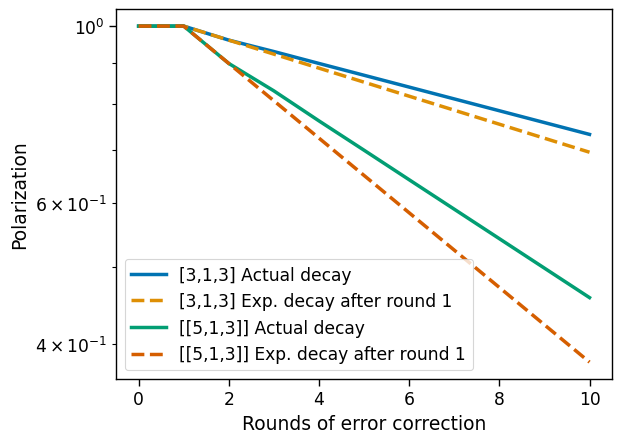

In [36]:
plt.plot(rep_polarization, label="[3,1,3] Actual decay")
plt.plot(rep_markov_polarization, label = "[3,1,3] Exp. decay after round 1", linestyle= "--")
plt.plot(FiveQB_polarization, label="[[5,1,3]] Actual decay")
plt.plot(FiveQB_markov_polarization, label = "[[5,1,3]] Exp. decay after round 1", linestyle = "--")

plt.legend()
plt.yscale('log')
plt.plot()
plt.xlabel("Rounds of error correction")
plt.ylabel(u'Polarization')
#plt.savefig("CombinedLogicalPolarizationprobpt1.pdf", bbox_inches="tight")


#### Logical error rate

In [37]:
seaborn.set_context("notebook", font_scale=1.5, rc={"lines.linewidth": 2.5})

Text(0, 0.5, 'Logical error rate')

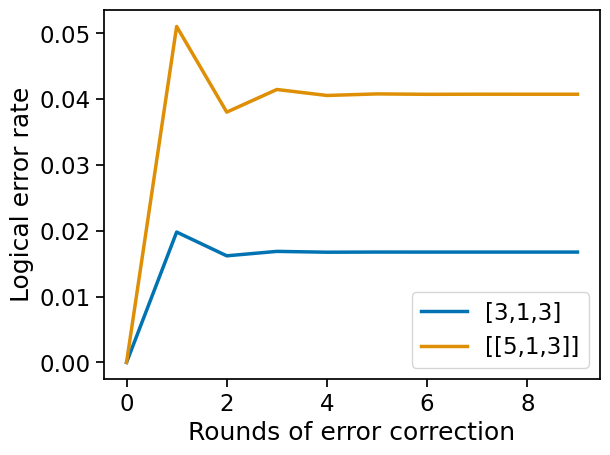

In [38]:
plt.plot(rep_error_rates,label="[3,1,3]")


plt.plot(FiveQB_error_rates, label="[[5,1,3]]")
plt.legend()

plt.xlabel("Rounds of error correction")
plt.ylabel('Logical error rate')
#plt.savefig("CombinedErrorRateprobpt1log.pdf", bbox_inches="tight")

#### Absolute value of change in logical error rate

In [39]:
seaborn.set_context("notebook", font_scale=1.45, rc={"lines.linewidth": 2.5})

/Users/jaziyad/opt/anaconda3/envs/ENME/lib/python3.13/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


Text(0, 0.5, 'Absolute value of change in \n logical error rate')

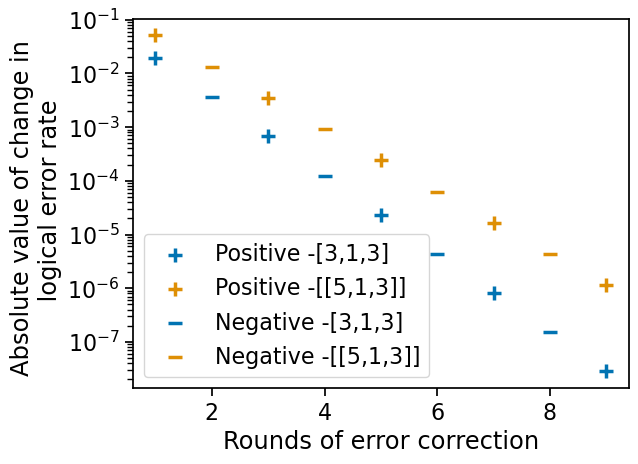

In [40]:

plt.scatter(range(1,10,2), rep_delta_error_rates_positive, label="Positive -[3,1,3]", marker="+", s=110, color="C0")

plt.scatter(range(1,10,2), FiveQB_delta_error_rates_positive, label="Positive -[[5,1,3]]", marker="+", s=110, color="C1")

plt.scatter(range(2,10,2), rep_delta_error_rates_negative, label="Negative -[3,1,3]", marker="_", s=110, color="C0")

plt.yscale('log')
plt.scatter(range(2,10,2), FiveQB_delta_error_rates_negative, label="Negative -[[5,1,3]]", marker="_", s=110, color="C1")
plt.legend()

plt.xlabel("Rounds of error correction")
plt.ylabel('Absolute value of change in \n logical error rate')

#plt.savefig("CombinedErrorRateChangeABSmarkersprobpt1log.pdf", bbox_inches="tight")